# Central-bank balance sheets since 2006

Annual end-of-period total assets for **24 selected monetary authorities**, using the BIS *Central bank total assets* dataset (`BIS,WS_CBTA,1.0`). The saved snapshot was retrieved on **15 October 2026** and has complete annual coverage for **2006–2025**. This is a latest-revised snapshot, not real-time historical vintages.

The sample contains the G20 monetary jurisdictions available in this source, with euro-area members represented by the **consolidated Eurosystem**, plus Switzerland, New Zealand, Sweden, Norway, Singapore, Hong Kong SAR, Thailand and Poland. Russia is not covered by this BIS dataset; this is a selected international comparison, not every central bank or a global aggregate.

Compare size in two ways:

\[
A^{USD}_{it}=\frac{A^{LCU,adj}_{it}}{e_{it}},\qquad
s_{it}=100\frac{A^{LCU,adj}_{it}}{GDP_{it}},
\]

where $e$ is local currency per US dollar. Both comparison series are supplied by BIS; this notebook does not estimate exchange rates or GDP. They are **adjusted for statistical breaks**. Unadjusted domestic-currency assets are also retained for accounting-level work.

Annual observations are December/end-of-period stocks, not annual averages. The source uses a four-quarter nominal GDP sum for its ratios. Recent monthly values are exported separately and never inserted as full-year 2026 observations. Dollar values are nominal and reflect exchange-rate and asset-valuation changes as well as balance-sheet transactions.

Sources: [BIS dataset](https://data.bis.org/topics/CBTA), [methodology and country sources](https://www.bis.org/statistics/cbta/cbta_doc.pdf), [API documentation](https://stats.bis.org/api-doc/v2/).

## 1. Settings and scope
Run from the repository root. The default uses the saved, checksum-verified snapshot and needs no network access. Set `REFRESH=True` to replace it with a new BIS download. Country selection and figure settings are editable here.

In [1]:
from pathlib import Path
import os
ROOT = Path.cwd()
assert (ROOT / "bis_data.py").exists(), "Launch this notebook from the project root."
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
import json
import sys
import importlib.metadata
from datetime import date
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from IPython.display import display, Image
from bis_data import load_snapshot, read_sdmx

START_YEAR = 2006
RECENT_MONTHLY_START = 2025
REFRESH = False
# Ordered, explicit BIS geography-code mapping; euro-area national banks are not added.
COUNTRIES = {
    "US": ("United States", "Federal Reserve System"),
    "XM": ("Euro area", "Eurosystem (ECB and national central banks)"),
    "JP": ("Japan", "Bank of Japan"),
    "CN": ("China", "People's Bank of China"),
    "GB": ("United Kingdom", "Bank of England"),
    "CH": ("Switzerland", "Swiss National Bank"),
    "CA": ("Canada", "Bank of Canada"),
    "AU": ("Australia", "Reserve Bank of Australia"),
    "NZ": ("New Zealand", "Reserve Bank of New Zealand"),
    "SE": ("Sweden", "Sveriges Riksbank"),
    "NO": ("Norway", "Norges Bank"),
    "KR": ("South Korea", "Bank of Korea"),
    "IN": ("India", "Reserve Bank of India"),
    "ID": ("Indonesia", "Bank Indonesia"),
    "BR": ("Brazil", "Central Bank of Brazil"),
    "MX": ("Mexico", "Bank of Mexico"),
    "AR": ("Argentina", "Central Bank of Argentina"),
    "ZA": ("South Africa", "South African Reserve Bank"),
    "TR": ("Türkiye", "Central Bank of the Republic of Türkiye"),
    "SA": ("Saudi Arabia", "Saudi Central Bank"),
    "SG": ("Singapore", "Monetary Authority of Singapore"),
    "HK": ("Hong Kong SAR", "Hong Kong Monetary Authority: Exchange Fund"),
    "TH": ("Thailand", "Bank of Thailand"),
    "PL": ("Poland", "Narodowy Bank Polski"),
}
CORE = ["US", "XM", "CN", "JP"]
COLORS = {"US": "#0072B2", "XM": "#D55E00", "CN": "#009E73", "JP": "#CC79A7"}
STYLES = {"US": "-", "XM": "--", "CN": "-.", "JP": ":"}
RAW, OUT, FIG = ROOT / "data/raw", ROOT / "data/processed", ROOT / "figures"
for folder in [OUT, FIG]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": "#cccccc",
    "axes.labelcolor": "#333333", "text.color": "#222222",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "axes.axisbelow": True, "pdf.fonttype": 42, "svg.fonttype": "none",
})

Matplotlib is building the font cache; this may take a moment.


## 2. Retrieve and inspect the source
The raw XML preserves source observations and metadata. The manifest records exact requests, retrieval times and SHA-256 hashes. `COMP_METHOD=B` means BIS-spliced; `TRANSFORMATION=B` means adjusted for breaks. These are different dimensions.

In [2]:
manifest = load_snapshot(RAW, COUNTRIES, START_YEAR, RECENT_MONTHLY_START, refresh=REFRESH)
annual_raw, annual_meta = read_sdmx(RAW / "annual.xml")
monthly_raw, monthly_meta = read_sdmx(RAW / "monthly_recent.xml")
retrieved = manifest[0]["retrieved_utc"][:10]
snapshot_year = int(retrieved[:4])
metadata = pd.concat([annual_meta, monthly_meta], ignore_index=True)
assert not metadata.series_key.duplicated().any()
assert set(annual_raw.REF_AREA) == set(COUNTRIES), "Missing or unexpected geography."
assert annual_raw.FREQ.eq("A").all()
assert annual_raw.COMP_METHOD.eq("B").all()
assert annual_raw.COLLECTION.eq("E").all(), "Expected end-of-period observations."
annual_raw["year"] = annual_raw.TIME_PERIOD.astype(int)
assert annual_raw.year.between(START_YEAR, snapshot_year - 1).all()
assert np.isfinite(annual_raw.OBS_VALUE).all(), "Missing or nonfinite source values: inspect before proceeding."
assert annual_raw.OBS_VALUE.gt(0).all()
assert annual_raw.OBS_STATUS.isin(["A", "B"]).all(), "Unexpected source flags: inspect their meaning."
# B marks observed breaks in the unadjusted local-currency series, not missing data.
assert annual_raw.loc[annual_raw.OBS_STATUS.eq("B"), "TRANSFORMATION"].eq("N").all()
assert annual_raw.loc[annual_raw.TRANSFORMATION.eq("B"), "OBS_STATUS"].eq("A").all()
# Multipliers matter: currency levels are billions; GDP ratios are percentages.
assert annual_raw.loc[annual_raw.UNIT_MEASURE.isin(["XDC", "USD"]), "UNIT_MULT"].eq(9).all()
assert annual_raw.loc[annual_raw.UNIT_MEASURE.eq("XDF_R_B1GQ"), "UNIT_MULT"].eq(0).all()
annual_raw.to_csv(OUT / "annual_observations.csv", index=False)
metadata.to_csv(OUT / "series_metadata.csv", index=False)
display(pd.DataFrame(manifest)[["file", "retrieved_utc", "bytes"]])
display(annual_raw.groupby(["UNIT_MEASURE", "TRANSFORMATION"]).agg(
    series=("series_key", "nunique"), observations=("OBS_VALUE", "size")))

,file,retrieved_utc,bytes
0,annual.xml,2026-10-15T10:42:19.362639+00:00,243951
1,monthly_recent.xml,2026-10-15T10:42:19.662633+00:00,176723
2,structure.xml,2026-10-15T10:42:21.126747+00:00,1512119
3,cbta_documentation.pdf,2026-10-15T10:42:22.602430+00:00,394419


series  observations
UNIT_MEASURE TRANSFORMATION                      
USD          B                   23           460
XDC          B                   24           480
             N                   24           480
XDF_R_B1GQ   B                   24           480

## 3. Construct the annual panel
Select four explicitly identified measures. US dollar levels for the United States come from its domestic-currency USD series because BIS does not supply a redundant converted series. All joins are one-to-one on geography and year. No interpolation, extrapolation, currency conversion or annual averaging is performed here.

The unadjusted source flags breaks for the UK in 2006 and 2013 and Thailand in 2018. These observations and their flags are retained. The comparison plots use the BIS break-adjusted series.

In [3]:
index_cols = ["REF_AREA", "year"]

def measure_frame(mask, name):
    selected = annual_raw.loc[mask, index_cols + ["OBS_VALUE", "series_key", "OBS_STATUS"]].copy()
    assert not selected.duplicated(index_cols).any(), f"Ambiguous series for {name}"
    assert set(selected.REF_AREA) == set(COUNTRIES), f"Missing country for {name}"
    return selected.rename(columns={
        "OBS_VALUE": name, "series_key": f"{name}_series", "OBS_STATUS": f"{name}_status"
    }).set_index(index_cols)

adjusted = annual_raw.TRANSFORMATION.eq("B")
usd_mask = adjusted & (
    annual_raw.UNIT_MEASURE.eq("USD") |
    (annual_raw.REF_AREA.eq("US") & annual_raw.UNIT_MEASURE.eq("XDC") & annual_raw.CURRENCY.eq("USD"))
)
measures = {
    "assets_usd_bn": usd_mask,
    "assets_pct_gdp": adjusted & annual_raw.UNIT_MEASURE.eq("XDF_R_B1GQ"),
    "assets_lcu_bn_adjusted": adjusted & annual_raw.UNIT_MEASURE.eq("XDC"),
    "assets_lcu_bn_reported": annual_raw.TRANSFORMATION.eq("N") & annual_raw.UNIT_MEASURE.eq("XDC"),
}
frames = [measure_frame(mask, name) for name, mask in measures.items()]
panel = frames[0]
for frame in frames[1:]:
    panel = panel.join(frame, how="outer", validate="one_to_one")
panel = panel.reset_index().rename(columns={"REF_AREA": "country_code"})
panel["country"] = panel.country_code.map({k: v[0] for k, v in COUNTRIES.items()})
panel["central_bank"] = panel.country_code.map({k: v[1] for k, v in COUNTRIES.items()})
lcu_meta = annual_meta.loc[annual_meta.UNIT_MEASURE.eq("XDC") & annual_meta.TRANSFORMATION.eq("N")]
assert not lcu_meta.REF_AREA.duplicated().any()
panel["currency"] = panel.country_code.map(lcu_meta.set_index("REF_AREA").CURRENCY)
panel["retrieved_utc"] = manifest[0]["retrieved_utc"]
panel["source"] = "BIS,WS_CBTA,1.0"
panel = panel.sort_values(["country_code", "year"]).reset_index(drop=True)
assert not panel[list(measures)].isna().any().any(), "Incomplete measure join."
LAST_YEAR = int(panel.year.max())
expected = pd.MultiIndex.from_product([sorted(COUNTRIES), range(START_YEAR, LAST_YEAR + 1)], names=["country_code", "year"])
actual = pd.MultiIndex.from_frame(panel[["country_code", "year"]])
assert actual.equals(expected), "Annual panel has gaps; inspect coverage before plotting."
assert panel.country.nunique() == len(COUNTRIES)
panel.to_csv(OUT / "annual_balance_sheets.csv", index=False)
for metric in ["assets_usd_bn", "assets_pct_gdp"]:
    panel.pivot(index="year", columns="country", values=metric).to_csv(OUT / f"annual_{metric}_wide.csv")
coverage = panel.groupby(["country_code", "country", "central_bank"]).agg(
    first_year=("year", "min"), last_year=("year", "max"), years=("year", "size"),
).reset_index()
coverage["missing_years"] = coverage.last_year - coverage.first_year + 1 - coverage.years
coverage.to_csv(OUT / "coverage.csv", index=False)
latest_annual = panel.loc[panel.year.eq(LAST_YEAR)].sort_values("assets_usd_bn", ascending=False)
latest_annual.to_csv(OUT / "latest_annual.csv", index=False)
display(latest_annual[["country", "year", "assets_usd_bn", "assets_pct_gdp"]].round(2).reset_index(drop=True))
print(f"{len(COUNTRIES)} authorities × {LAST_YEAR - START_YEAR + 1} years = {len(panel)} complete country-years.")

,country,year,assets_usd_bn,assets_pct_gdp
0,Euro area,2025,7427.91,39.71
1,China,2025,6878.87,34.37
2,United States,2025,6640.62,21.59
3,Japan,2025,4326.07,101.70
4,Switzerland,2025,1127.64,103.00
5,United Kingdom,2025,1065.17,26.04
6,India,2025,921.73,24.47
7,Brazil,2025,907.94,39.04
8,Singapore,2025,617.12,100.53
9,Hong Kong SAR,2025,534.57,125.06


24 authorities × 20 years = 480 complete country-years.


## 4. Verify timing and retain the latest monthly observations
Check annual 2025 levels against December 2025 observations independently returned by the monthly API query. Ratios are excluded from this check because the monthly feed does not provide GDP ratios. The latest monthly table retains a date for each value; countries have different reporting lags.

In [4]:
assert monthly_raw.FREQ.eq("M").all()
assert set(monthly_raw.REF_AREA) == set(COUNTRIES)
monthly_raw["month"] = pd.to_datetime(monthly_raw.TIME_PERIOD, format="%Y-%m")
assert monthly_raw.month.lt(pd.Timestamp(f"{snapshot_year + 1}-01-01")).all()
assert np.isfinite(monthly_raw.OBS_VALUE).all()
# Compare the common final annual year using frequency-independent keys.
match_dims = ["REF_AREA", "COMP_METHOD", "UNIT_MEASURE", "CURRENCY", "TRANSFORMATION"]
a = annual_raw.loc[annual_raw.year.eq(LAST_YEAR) & annual_raw.UNIT_MEASURE.ne("XDF_R_B1GQ")]
m = monthly_raw.loc[monthly_raw.TIME_PERIOD.eq(f"{LAST_YEAR}-12")]
crosscheck = a.merge(m, on=match_dims, suffixes=("_annual", "_monthly"), validate="one_to_one")
assert len(crosscheck) == len(a), "Missing December counterpart."
crosscheck["absolute_difference"] = (crosscheck.OBS_VALUE_annual - crosscheck.OBS_VALUE_monthly).abs()
assert np.allclose(crosscheck.OBS_VALUE_annual, crosscheck.OBS_VALUE_monthly, rtol=1e-10, atol=1e-8)
crosscheck[match_dims + ["OBS_VALUE_annual", "OBS_VALUE_monthly", "absolute_difference"]].to_csv(
    OUT / "annual_december_crosscheck.csv", index=False)
monthly_raw.to_csv(OUT / "monthly_recent_observations.csv", index=False)
monthly_latest = monthly_raw.sort_values("month").groupby("series_key", as_index=False).tail(1).copy()
monthly_latest["country"] = monthly_latest.REF_AREA.map({k: v[0] for k, v in COUNTRIES.items()})
monthly_latest["annual_observation"] = False
monthly_latest.to_csv(OUT / "latest_monthly_by_series.csv", index=False)
latest_usd = monthly_latest.loc[
    monthly_latest.TRANSFORMATION.eq("B") & (
        monthly_latest.UNIT_MEASURE.eq("USD") |
        (monthly_latest.REF_AREA.eq("US") & monthly_latest.UNIT_MEASURE.eq("XDC") & monthly_latest.CURRENCY.eq("USD"))
    ), ["REF_AREA", "country", "TIME_PERIOD", "OBS_VALUE", "series_key"]
].rename(columns={"REF_AREA": "country_code", "TIME_PERIOD": "month", "OBS_VALUE": "assets_usd_bn"})
assert len(latest_usd) == len(COUNTRIES)
latest_usd.sort_values("country").to_csv(OUT / "latest_monthly_usd.csv", index=False)
print(f"Annual/December equality passed for {len(crosscheck)} level series in {LAST_YEAR}.")
display(latest_usd.sort_values("country").reset_index(drop=True))

Annual/December equality passed for 71 level series in 2025.


,country_code,country,month,assets_usd_bn,series_key
0,AR,Argentina,2026-07,132.821395,M.AR.B.USD._Z.B
1,AU,Australia,2026-06,251.017912,M.AU.B.USD._Z.B
2,BR,Brazil,2026-06,970.836852,M.BR.B.USD._Z.B
3,CA,Canada,2026-07,166.402202,M.CA.B.USD._Z.B
4,CN,China,2026-06,7285.165826,M.CN.B.USD._Z.B
5,XM,Euro area,2026-07,6823.522656,M.XM.B.USD._Z.B
6,HK,Hong Kong SAR,2026-06,569.200088,M.HK.B.USD._Z.B
7,IN,India,2026-06,921.499301,M.IN.B.USD._Z.B
8,ID,Indonesia,2026-05,274.197092,M.ID.B.USD._Z.B
9,JP,Japan,2026-07,4020.940133,M.JP.B.USD._Z.B


## 5. Plot the annual results
The overview highlights four large monetary jurisdictions on shared scales. The full-sample figures include every selected authority. Dollar facets have their own labelled vertical scales to reveal changes in smaller balance sheets; GDP-ratio facets share the same scale for comparisons. End labels show the final annual observation.

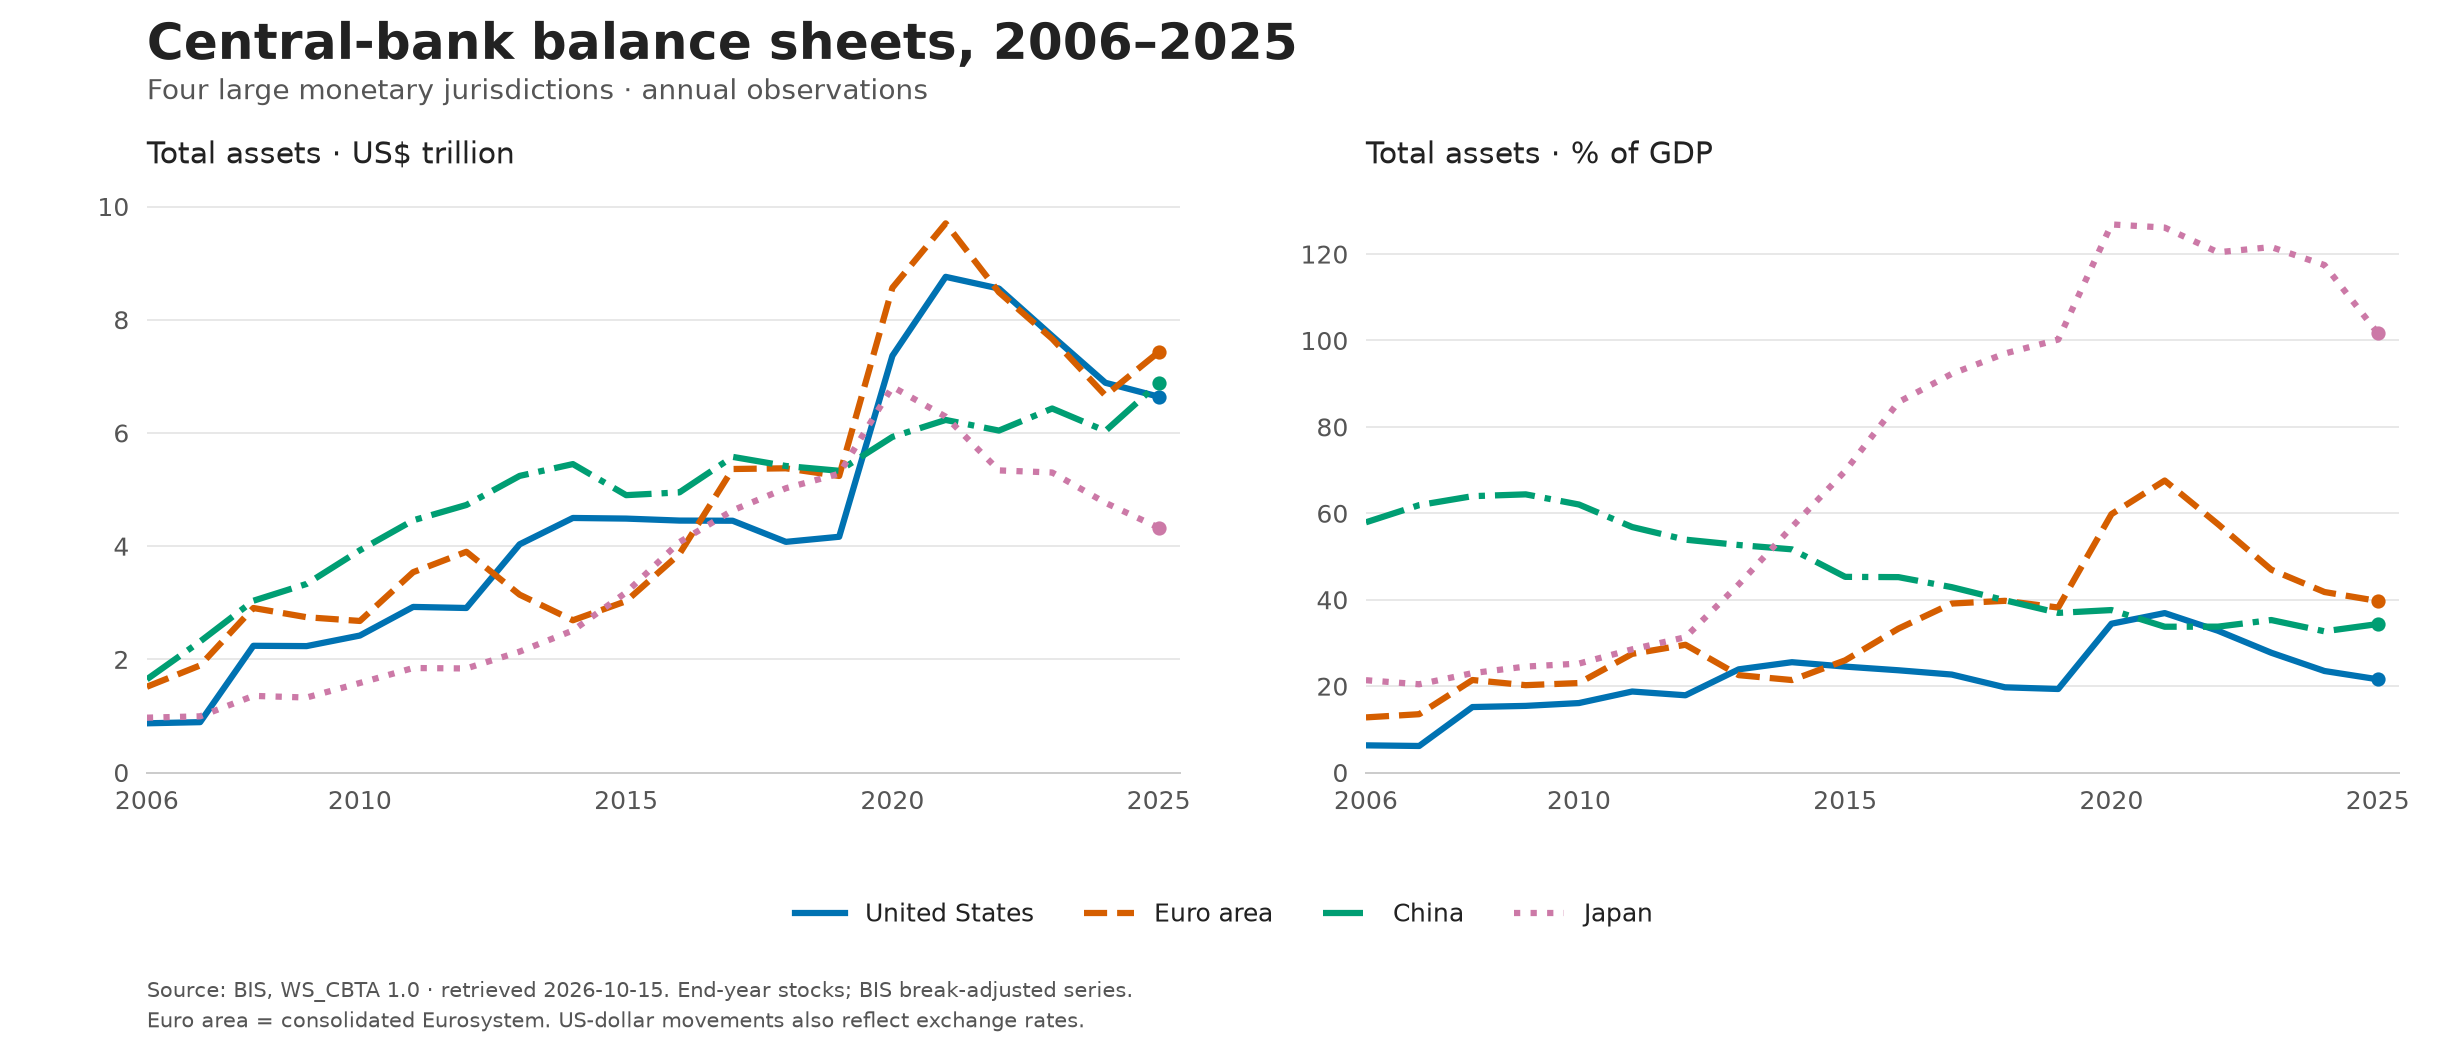

In [5]:
SOURCE_NOTE = f"Source: BIS, WS_CBTA 1.0 · retrieved {retrieved}. End-year stocks; BIS break-adjusted series."

def save_figure(fig, name):
    for extension in ["png", "pdf", "svg"]:
        fig.savefig(FIG / f"{name}.{extension}", dpi=180, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(FIG / f"{name}.png"), width=1000))

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.8))
for ax, metric, divisor, title in zip(
    axes, ["assets_usd_bn", "assets_pct_gdp"], [1000, 1],
    ["Total assets · US$ trillion", "Total assets · % of GDP"]
):
    for country_code in CORE:
        series = panel.loc[panel.country_code.eq(country_code)]
        ax.plot(series.year, series[metric] / divisor, color=COLORS[country_code],
                linestyle=STYLES[country_code], linewidth=2.5, label=COUNTRIES[country_code][0])
        ax.scatter(series.year.iloc[-1], series[metric].iloc[-1] / divisor,
                   color=COLORS[country_code], s=22, zorder=3)
    ax.set_title(title, loc="left", fontsize=12, pad=14)
    ax.set_ylim(bottom=0)
    ax.set_xlim(START_YEAR, LAST_YEAR + 0.4)
    ax.set_xticks(sorted(set([START_YEAR, 2010, 2015, 2020, LAST_YEAR])))
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.7)
    ax.tick_params(axis="both", length=0, pad=7)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.09), ncol=4, frameon=False)
fig.suptitle(f"Central-bank balance sheets, {START_YEAR}–{LAST_YEAR}", x=0.06, ha="left", y=0.98, fontsize=20, weight="bold")
fig.text(0.06, 0.905, "Four large monetary jurisdictions · annual observations", fontsize=11, color="#555555")
fig.text(0.06, 0.045, SOURCE_NOTE, fontsize=8.5, color="#555555")
fig.text(0.06, 0.016, "Euro area = consolidated Eurosystem. US-dollar movements also reflect exchange rates.", fontsize=8.5, color="#555555")
fig.subplots_adjust(left=0.06, right=0.98, top=0.81, bottom=0.26, wspace=0.18)
save_figure(fig, "major_central_banks_overview")

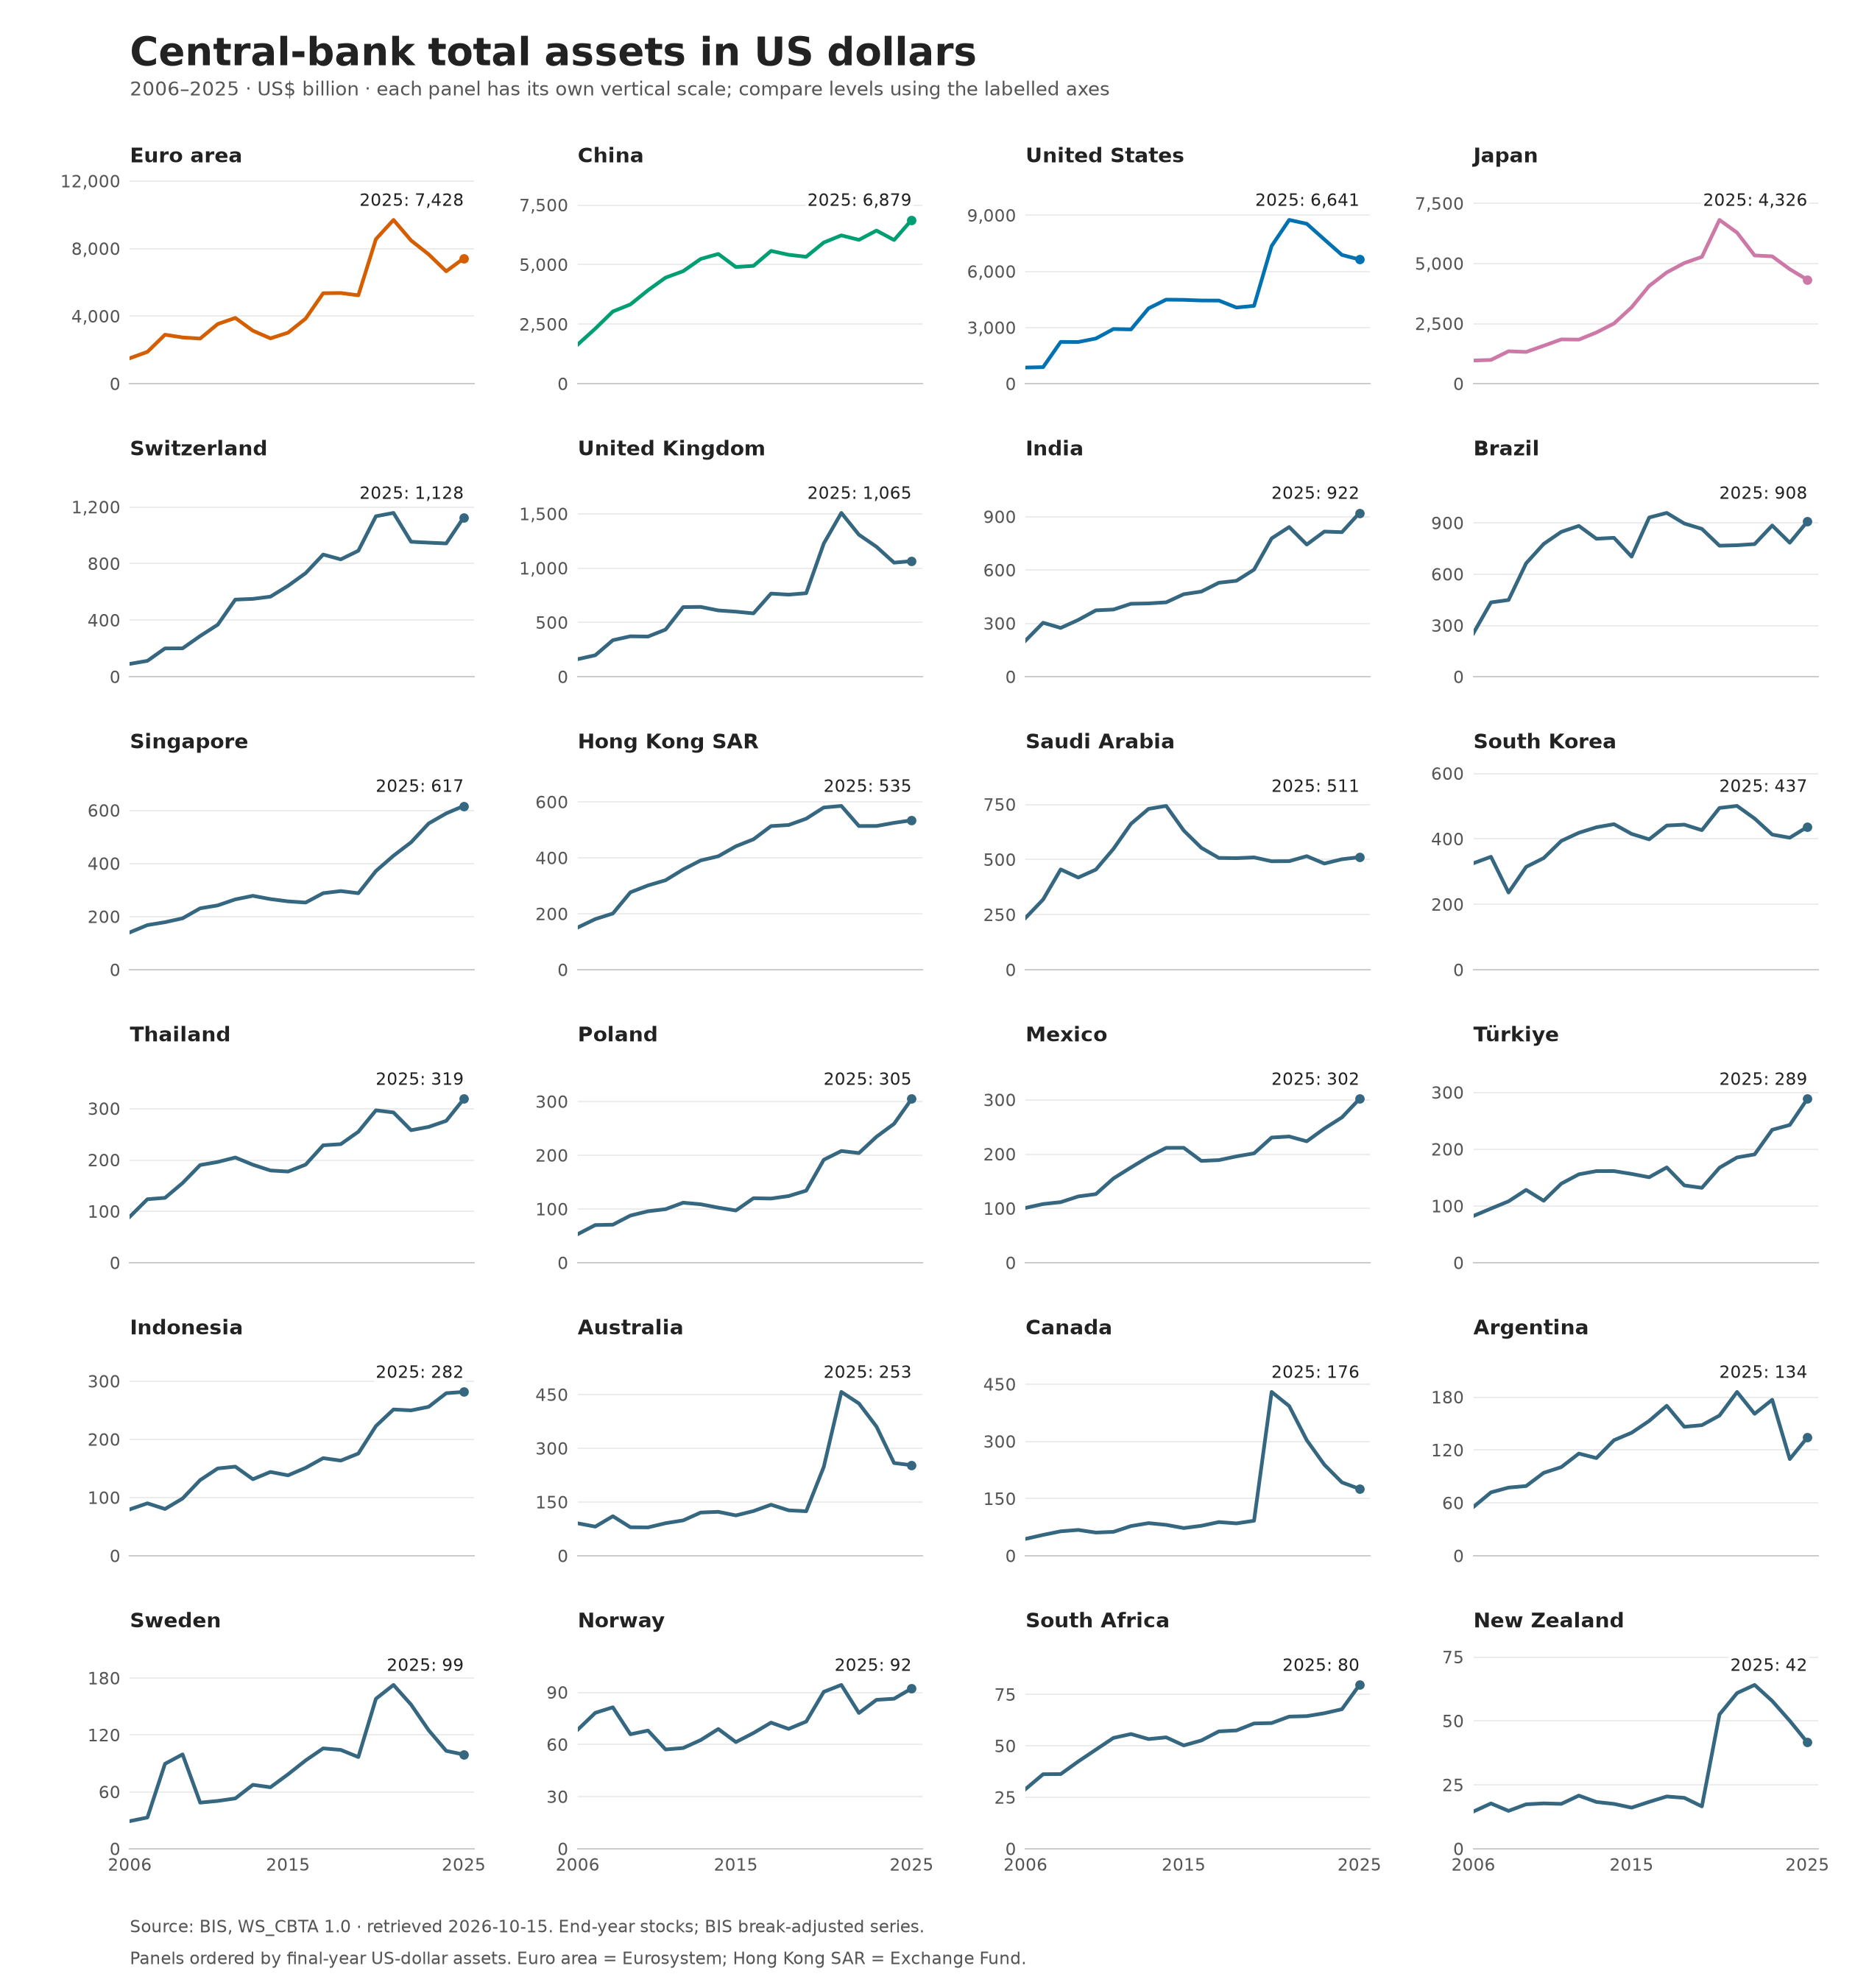

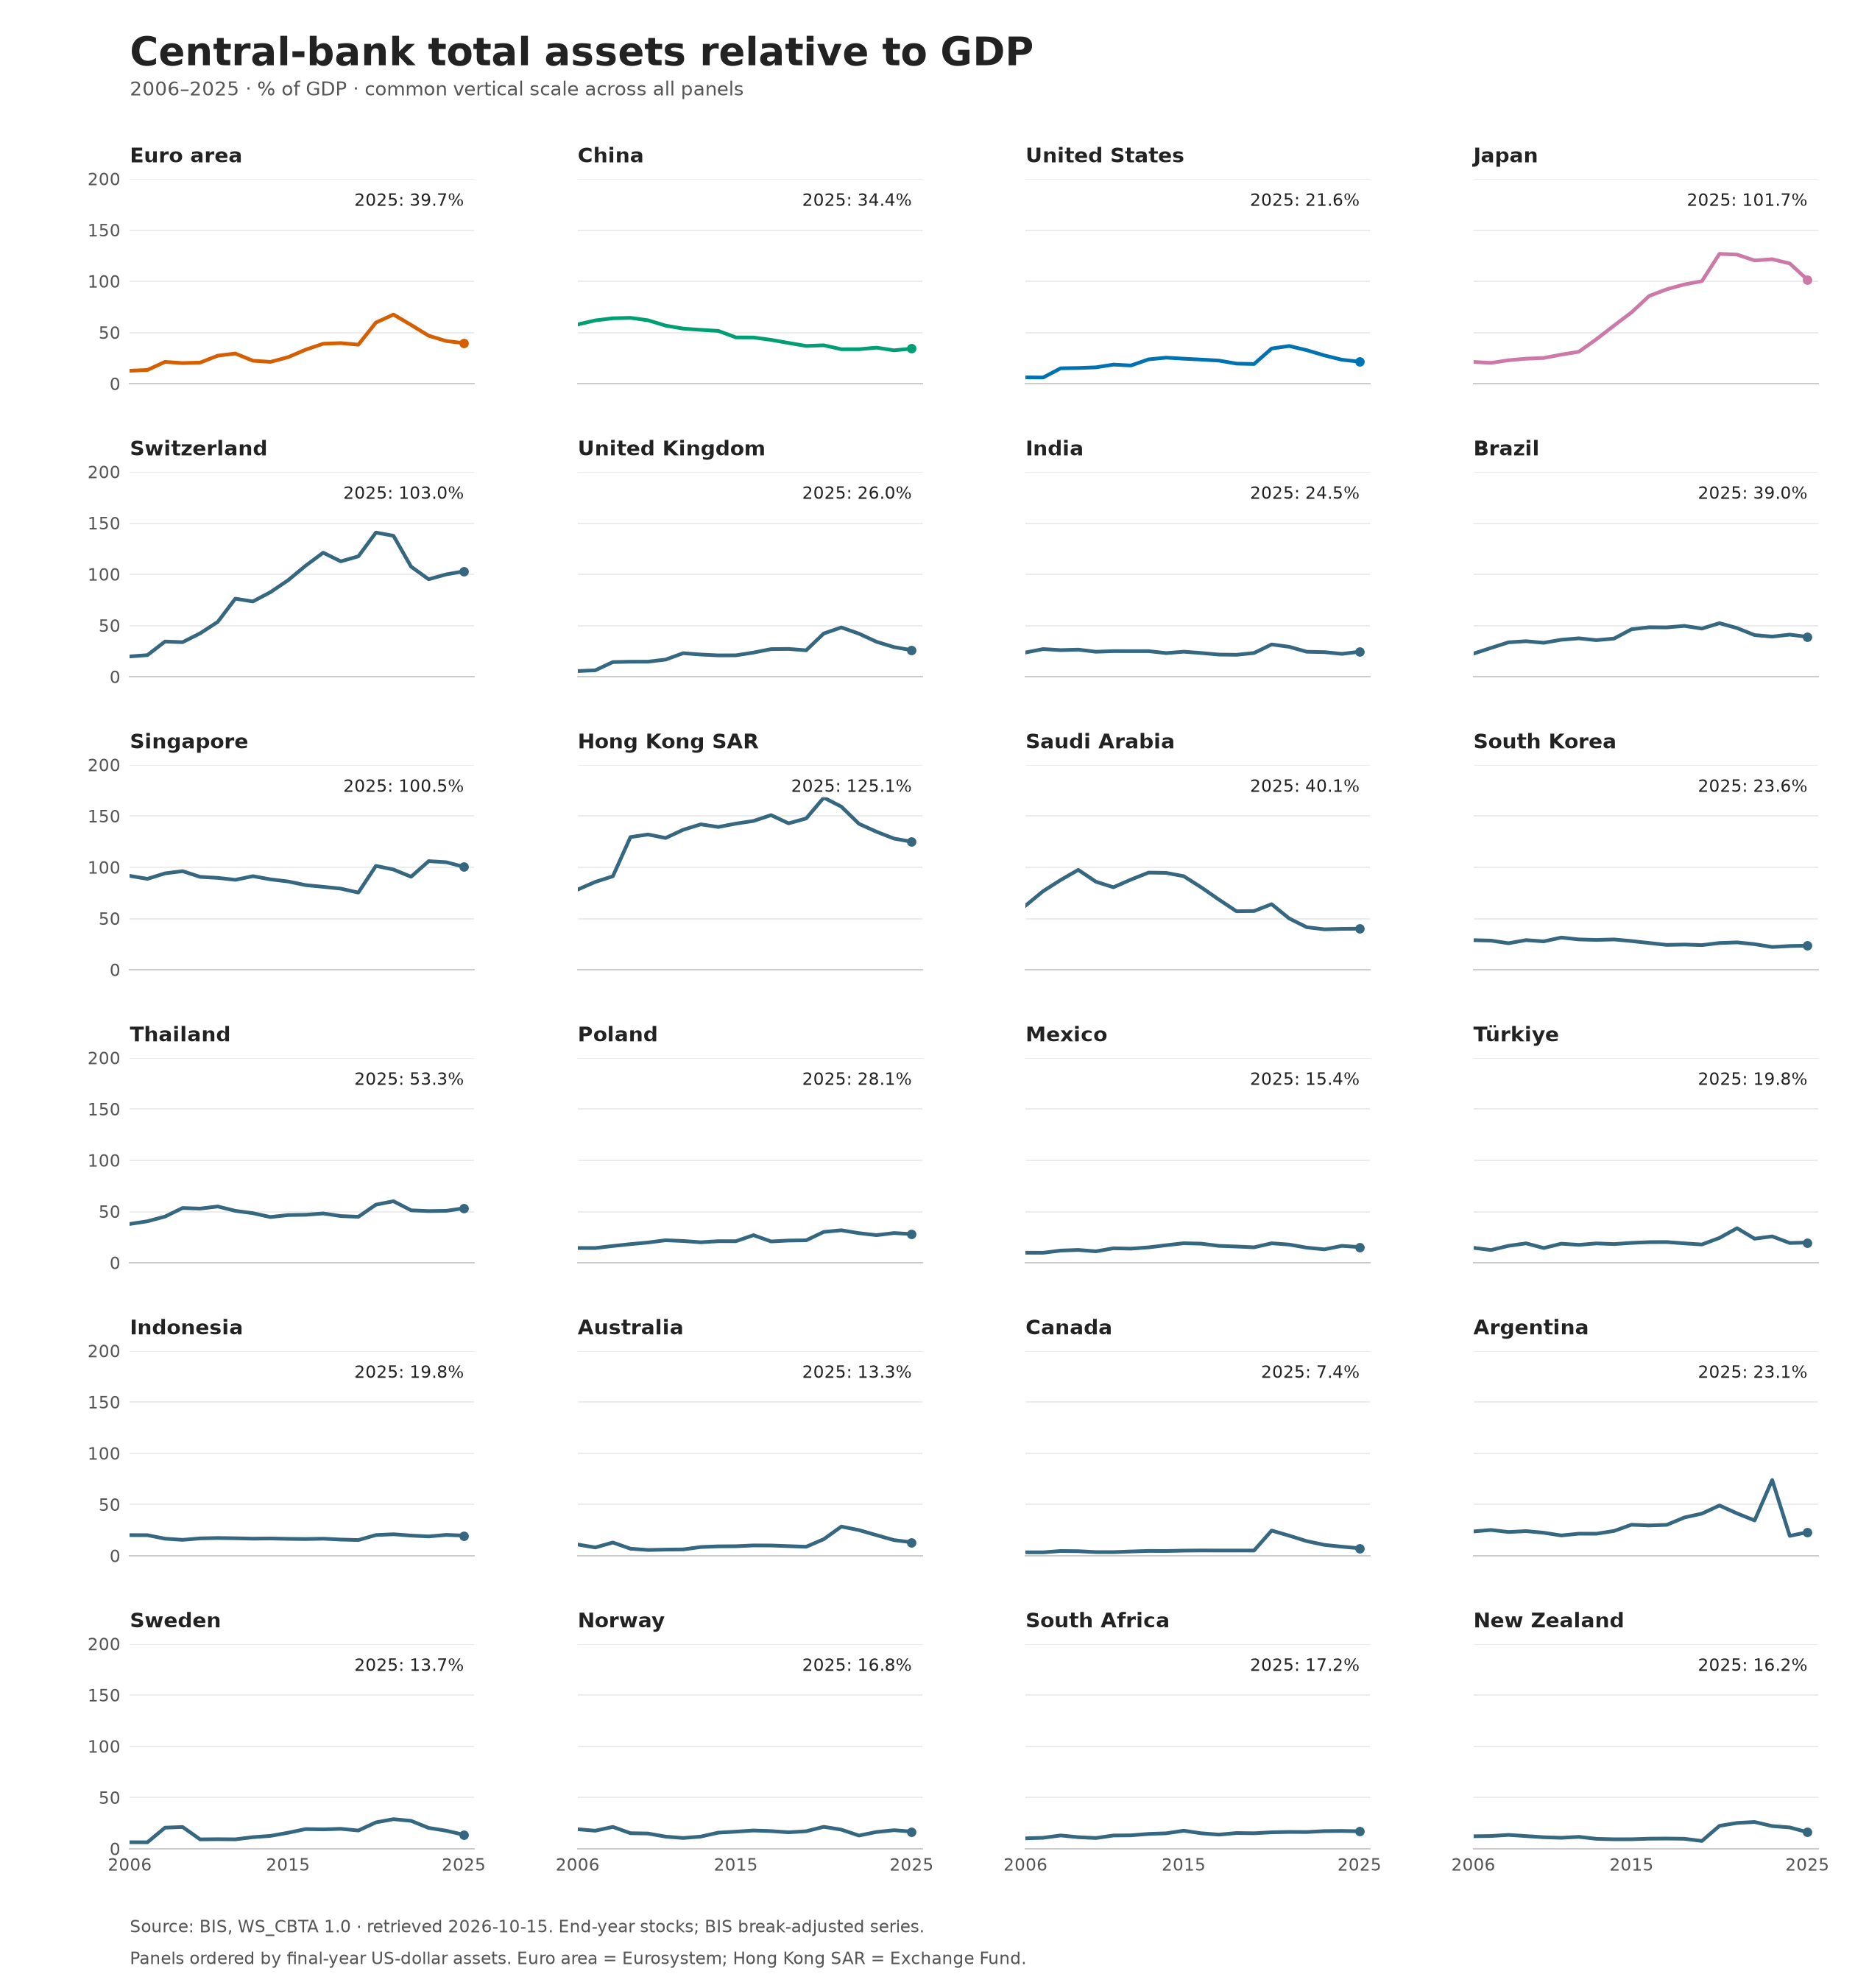

In [6]:
# Fixed ordering by final-year dollar assets, shared across both facet figures.
order = latest_annual.country_code.tolist()
shared_gdp_max = np.ceil(panel.assets_pct_gdp.max() / 50) * 50
for metric, filename, title, subtitle in [
    ("assets_usd_bn", "all_central_banks_usd", "Central-bank total assets in US dollars",
     "US$ billion · each panel has its own vertical scale; compare levels using the labelled axes"),
    ("assets_pct_gdp", "all_central_banks_gdp", "Central-bank total assets relative to GDP",
     "% of GDP · common vertical scale across all panels"),
]:
    fig, axes = plt.subplots(6, 4, figsize=(14, 15), sharex=True, sharey=(metric == "assets_pct_gdp"))
    for ax, country_code in zip(axes.flat, order):
        series = panel.loc[panel.country_code.eq(country_code)]
        color = COLORS.get(country_code, "#356780")
        ax.plot(series.year, series[metric], color=color, linewidth=2)
        ax.scatter(LAST_YEAR, series[metric].iloc[-1], color=color, s=17, zorder=3)
        ax.set_title(COUNTRIES[country_code][0], loc="left", fontsize=11, weight="bold", pad=9)
        end_value = series[metric].iloc[-1]
        value_label = f"{LAST_YEAR}: {end_value:,.0f}" if metric == "assets_usd_bn" else f"{LAST_YEAR}: {end_value:.1f}%"
        ax.text(0.97, 0.93, value_label, transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1})
        ax.set_ylim(0, shared_gdp_max if metric == "assets_pct_gdp" else series[metric].max() * 1.25)
        ax.set_xlim(START_YEAR, LAST_YEAR + 0.6)
        ax.set_xticks([START_YEAR, 2015, LAST_YEAR])
        if metric == "assets_pct_gdp":
            ax.set_yticks([0, 50, 100, 150, 200])
        else:
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.grid(axis="y", color="#e6e6e6", linewidth=0.6)
        ax.tick_params(axis="both", length=0, pad=5, labelsize=9)
    fig.suptitle(title, x=0.07, ha="left", y=0.982, fontsize=21, weight="bold")
    fig.text(0.07, 0.952, f"{START_YEAR}–{LAST_YEAR} · {subtitle}", fontsize=10.5, color="#555555")
    fig.text(0.07, 0.028, SOURCE_NOTE, fontsize=9, color="#555555")
    fig.text(0.07, 0.012, "Panels ordered by final-year US-dollar assets. Euro area = Eurosystem; Hong Kong SAR = Exchange Fund.", fontsize=9, color="#555555")
    fig.subplots_adjust(left=0.07, right=0.98, top=0.91, bottom=0.07, hspace=0.43, wspace=0.30)
    save_figure(fig, filename)

## 6. Validation record and interpretation
All three figures use the same 480-row panel. Annual coverage, units, statuses, duplicates, complete joins and annual/December agreement are checked above. USD differences should not be interpreted as asset purchases alone, and GDP shares also move with nominal GDP. Institutions differ in mandates, asset composition and accounting practices; these are size comparisons, not a measure of policy stance or effectiveness. Norges Bank excludes the Government Pension Fund Global; Hong Kong uses the Exchange Fund. Source-specific compilation notes are preserved in `series_metadata.csv`.

In [7]:
# Confirm representative CSV values round-trip to the unchanged source observations.
saved = pd.read_csv(OUT / "annual_balance_sheets.csv")
spot_checks = []
for country_code, year in [("US", START_YEAR), ("XM", 2020), ("CN", LAST_YEAR), ("JP", LAST_YEAR), ("CH", LAST_YEAR)]:
    row = saved.loc[saved.country_code.eq(country_code) & saved.year.eq(year)].iloc[0]
    for metric in ["assets_usd_bn", "assets_pct_gdp", "assets_lcu_bn_reported"]:
        original = annual_raw.loc[annual_raw.series_key.eq(row[f"{metric}_series"]) & annual_raw.year.eq(year), "OBS_VALUE"]
        assert len(original) == 1
        assert np.isclose(row[metric], original.iloc[0], rtol=1e-12)
        spot_checks.append({"country": country_code, "year": year, "measure": metric, "value": float(original.iloc[0])})
versions = {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
validation = {
    "snapshot_date": retrieved, "countries": len(COUNTRIES), "first_year": START_YEAR,
    "last_year": LAST_YEAR, "country_years": len(panel), "missing_country_years": 0,
    "source_series": int(annual_raw.series_key.nunique()), "source_observations": len(annual_raw),
    "annual_december_level_comparisons": len(crosscheck),
    "max_annual_december_absolute_difference": float(crosscheck.absolute_difference.max()),
    "annual_status_counts": annual_raw.OBS_STATUS.value_counts().to_dict(),
    "latest_month_min": latest_usd.month.min(), "latest_month_max": latest_usd.month.max(),
    "source_spot_checks": spot_checks, "python": sys.version.split()[0], "packages": versions,
}
(OUT / "validation.json").write_text(json.dumps(validation, indent=2) + "\n")
print(json.dumps({k: v for k, v in validation.items() if k != "source_spot_checks"}, indent=2))
# Inspect peak and final GDP shares without imposing an interpretation on the movements.
peaks = panel.loc[panel.groupby("country_code").assets_pct_gdp.idxmax(), ["country_code", "year", "assets_pct_gdp"]]
summary = latest_annual[["country_code", "country", "assets_pct_gdp"]].merge(peaks, on="country_code", suffixes=("_latest", "_peak"))
display(summary.sort_values("assets_pct_gdp_latest", ascending=False).round(2).reset_index(drop=True))

{
  "snapshot_date": "2026-10-15",
  "countries": 24,
  "first_year": 2006,
  "last_year": 2025,
  "country_years": 480,
  "missing_country_years": 0,
  "source_series": 95,
  "source_observations": 1900,
  "annual_december_level_comparisons": 71,
  "max_annual_december_absolute_difference": 0.0,
  "annual_status_counts": {
    "A": 1897,
    "B": 3
  },
  "latest_month_min": "2026-05",
  "latest_month_max": "2026-07",
  "python": "3.14.7",
  "packages": {
    "pandas": "3.0.6",
    "numpy": "2.5.3",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.3.0"
  }
}


,country_code,country,assets_pct_gdp_latest,year,assets_pct_gdp_peak
0,HK,Hong Kong SAR,125.06,2020,168.09
1,CH,Switzerland,103.00,2020,140.82
2,JP,Japan,101.70,2020,126.86
3,SG,Singapore,100.53,2023,106.08
4,TH,Thailand,53.25,2021,60.12
5,SA,Saudi Arabia,40.13,2009,97.56
6,XM,Euro area,39.71,2021,67.59
7,BR,Brazil,39.04,2020,52.37
8,CN,China,34.37,2009,64.39
9,PL,Poland,28.06,2021,31.79
